# Linear models: TF-IDF + LogisticRegression / LinearSVC

Iterating from a LogisticRegression baseline to a tuned LinearSVC model for the Apar feedback classification task. Uses a word TF-IDF + char TF-IDF + tag one-hot feature pipeline, then runs a series of experiments (n-gram range, cross-lingual keyword normalization, classifier choice, regularization strength, decision-threshold tuning, sublinear TF) to reach a final tuned configuration.

**Final result:** LinearSVC, C=0.5, sublinear_tf=True, class_weight="balanced" -> **0.8879 mean CV Macro F1**, **0.89901 public leaderboard score** (solo; this component is used as part of two locked blend submissions -- see this bundle's `docs/` for those). Production code for this model lives in `src/linear_model.py`, `src/train_linear.py`.

## Setup

In [3]:
# %pip install -r requirements.txt

In [4]:
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

RANDOM_SEED = 42
N_SPLITS = 5

## Load data

In [5]:
train = pd.read_csv("data/train.csv")
train.shape

(17769, 4)

## Preprocessing

Lowercase, collapse 3+ repeated characters down to 2 (normalizes noisy emphasis like "!!!!!" or "goood" while keeping mild doubling), collapse whitespace, and fill missing `tag` with an explicit "missing" category.

In [ ]:
TAG_MISSING_VALUE = "missing"


def clean_text(text: str) -> str:
    text = text.lower()
    text = re.sub(r"(.)\1{2,}", r"\1\1", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text


def prepare_dataframe(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df["feedback"] = df["feedback"].astype(str).apply(clean_text)
    df["tag"] = df["tag"].fillna(TAG_MISSING_VALUE)
    return df


train = prepare_dataframe(train)
train.head()

_[Output redacted: this cell printed rows of raw feedback text from the competition dataset. Per the competition rules ("the datasets provided ... can only be used for the sole purpose of participating ... transferring ... to any public platform is strictly prohibited"), that output is not included in this bundle. The code is unchanged and will reproduce the same output locally against your own copy of train.csv.]_

## Feature pipeline

Word-level TF-IDF (uni+bi-grams) and char-level TF-IDF (3-5 char n-grams, robust to spelling/diacritic variation) on `feedback`, plus one-hot encoding of `tag`.

In [7]:
WORD_NGRAM_RANGE = (1, 2)
CHAR_NGRAM_RANGE = (3, 5)
WORD_MIN_DF = 2
CHAR_MIN_DF = 2


def build_feature_pipeline() -> ColumnTransformer:
    word_tfidf = TfidfVectorizer(ngram_range=WORD_NGRAM_RANGE, min_df=WORD_MIN_DF)
    char_tfidf = TfidfVectorizer(
        ngram_range=CHAR_NGRAM_RANGE, min_df=CHAR_MIN_DF, analyzer="char_wb"
    )
    tag_encoder = OneHotEncoder(handle_unknown="ignore")

    return ColumnTransformer(
        transformers=[
            ("word_tfidf", word_tfidf, "feedback"),
            ("char_tfidf", char_tfidf, "feedback"),
            ("tag_ohe", tag_encoder, ["tag"]),
        ]
    )


def build_model_pipeline() -> Pipeline:
    return Pipeline(
        steps=[
            ("features", build_feature_pipeline()),
            (
                "classifier",
                LogisticRegression(
                    class_weight="balanced",
                    max_iter=1000,
                    random_state=RANDOM_SEED,
                ),
            ),
        ]
    )

## Cross-validation with out-of-fold predictions

Stratified 5-fold CV; keeps every row's out-of-fold prediction, enabling error inspection afterwards (confusion matrix, misclassified examples) without retraining.

In [8]:
X = train[["feedback", "tag"]]
y = train["label"]

skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_SEED)

fold_macro_f1 = []
oof_pred = pd.Series(index=train.index, dtype=object)

for fold_idx, (train_idx, val_idx) in enumerate(skf.split(X, y), start=1):
    X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

    model = build_model_pipeline()
    model.fit(X_train, y_train)
    y_pred = model.predict(X_val)

    macro_f1 = f1_score(y_val, y_pred, average="macro")
    fold_macro_f1.append(macro_f1)
    oof_pred.iloc[val_idx] = y_pred

    print(f"Fold {fold_idx}: Macro F1 = {macro_f1:.4f}")

print(f"\nMean Macro F1: {np.mean(fold_macro_f1):.4f} (+/- {np.std(fold_macro_f1):.4f})")

train["oof_pred"] = oof_pred

Fold 1: Macro F1 = 0.8780
Fold 2: Macro F1 = 0.8721
Fold 3: Macro F1 = 0.8877
Fold 4: Macro F1 = 0.8781
Fold 5: Macro F1 = 0.8658

Mean Macro F1: 0.8763 (+/- 0.0073)


In [9]:
print(classification_report(train["label"], train["oof_pred"], digits=4))

                   precision    recall  f1-score   support

 customer_support     0.8209    0.8680    0.8438      3327
            other     0.8106    0.9045    0.8550      3800
technical_support     0.9593    0.9025    0.9300     10642

         accuracy                         0.8964     17769
        macro avg     0.8636    0.8917    0.8763     17769
     weighted avg     0.9016    0.8964    0.8978     17769



**Finding:** LogisticRegression baseline scores **0.8763 mean Macro F1**. `technical_support` is easiest (F1 0.93); `other` and `customer_support` are weaker (F1 ~0.85), with `customer_support` the lowest — consistent with it being the smallest class and the one most easily confused with `technical_support`.

## Confusion matrix heatmap

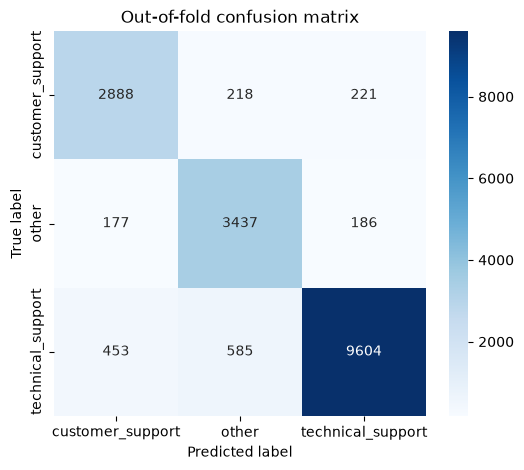

In [10]:
labels = sorted(y.unique())
cm = confusion_matrix(train["label"], train["oof_pred"], labels=labels)
cm_df = pd.DataFrame(cm, index=labels, columns=labels)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_df, annot=True, fmt="d", cmap="Blues")
plt.ylabel("True label")
plt.xlabel("Predicted label")
plt.title("Out-of-fold confusion matrix")
plt.show()

## Per-class F1 bar chart

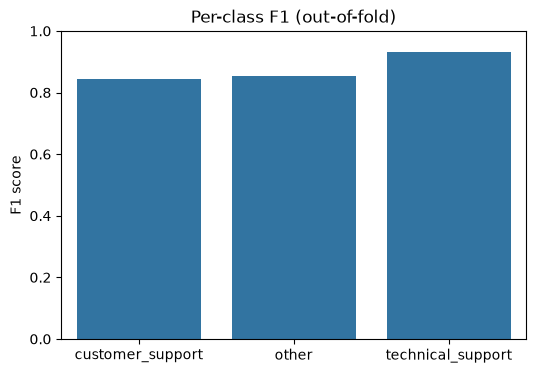

In [11]:
per_class_f1 = f1_score(train["label"], train["oof_pred"], labels=labels, average=None)

plt.figure(figsize=(6, 4))
sns.barplot(x=labels, y=per_class_f1)
plt.ylim(0, 1)
plt.ylabel("F1 score")
plt.title("Per-class F1 (out-of-fold)")
plt.show()

## Inspect misclassified examples

Focused on true=technical_support rows predicted as other/customer_support, since the confusion matrix showed this as the largest error block.

In [12]:
misclassified = train[train["label"] != train["oof_pred"]]
misclassified.shape

(1840, 5)

In [ ]:
tech_as_other = misclassified[
    (misclassified["label"] == "technical_support") & (misclassified["oof_pred"] == "other")
]
tech_as_other[["feedback", "tag"]].sample(15, random_state=42)

_[Output redacted: this cell printed rows of raw feedback text from the competition dataset. Per the competition rules ("the datasets provided ... can only be used for the sole purpose of participating ... transferring ... to any public platform is strictly prohibited"), that output is not included in this bundle. The code is unchanged and will reproduce the same output locally against your own copy of train.csv.]_

In [ ]:
tech_as_customer = misclassified[
    (misclassified["label"] == "technical_support") & (misclassified["oof_pred"] == "customer_support")
]
tech_as_customer[["feedback", "tag"]].sample(15, random_state=42)

_[Output redacted: this cell printed rows of raw feedback text from the competition dataset. Per the competition rules ("the datasets provided ... can only be used for the sole purpose of participating ... transferring ... to any public platform is strictly prohibited"), that output is not included in this bundle. The code is unchanged and will reproduce the same output locally against your own copy of train.csv.]_

**Finding:** the largest confusion is `technical_support` leaking into `other` and `customer_support`. `technical_support` -> `other` errors tend to be vague/short phrasing without specific part names ("it is not smooth", "nithing works") or sarcastic/sentiment-heavy tone that reads like generic feedback. `technical_support` -> `customer_support` errors are dominated by **activation/unlock language** ("kilid açılmadı", "aktivləşmədi") — investigated further below.

## Activation/unlock keyword analysis

In [15]:
activation_keywords = r"aktiv|kilid|kilit|активир|включ|начал|active|unlock|lock"

activation_mask = train["feedback"].str.contains(activation_keywords, case=False, regex=True, na=False)
activation_subset = train[activation_mask]
activation_subset.shape

(1076, 5)

In [16]:
activation_subset["label"].value_counts()

label
technical_support    592
customer_support     448
other                 36
Name: count, dtype: int64

In [17]:
pd.crosstab(activation_subset["tag"], activation_subset["label"])

label,customer_support,other,technical_support
tag,,,
Battery,4,0,2
Brakes,7,1,10
Chain,15,1,8
Control panel,0,0,1
Dirty,2,0,2
Display,0,0,5
Electrical system,8,0,7
Firmware,6,0,3
Frame,7,0,2


In [18]:
print(classification_report(activation_subset["label"], activation_subset["oof_pred"], digits=4))

                   precision    recall  f1-score   support

 customer_support     0.7917    0.8906    0.8382       448
            other     0.6154    0.6667    0.6400        36
technical_support     0.9231    0.8311    0.8747       592

         accuracy                         0.8504      1076
        macro avg     0.7767    0.7961    0.7843      1076
     weighted avg     0.8581    0.8504    0.8516      1076



**Finding:** ~6% of rows mention activation/unlock language, and within this subgroup the true label split is **55% technical_support / 42% customer_support / 3% other** — far more balanced than the overall dataset. This is a genuinely contested zone, not just model error. `tag` doesn't rescue it either: 48% of these rows have no tag, and even tagged rows split inconsistently. The model scores notably worse here (Macro F1 0.7843 vs. 0.8763 overall) — this is the model's real weak spot.

## Experiment: widen word n-grams to trigrams

Tested whether extending word TF-IDF from (1,2) to (1,3) captures more of the surrounding context around ambiguous phrases, without changing anything else in the pipeline.

In [19]:
WORD_NGRAM_RANGE_TRIGRAM = (1, 3)


def build_feature_pipeline_trigram() -> ColumnTransformer:
    word_tfidf = TfidfVectorizer(ngram_range=WORD_NGRAM_RANGE_TRIGRAM, min_df=WORD_MIN_DF)
    char_tfidf = TfidfVectorizer(
        ngram_range=CHAR_NGRAM_RANGE, min_df=CHAR_MIN_DF, analyzer="char_wb"
    )
    tag_encoder = OneHotEncoder(handle_unknown="ignore")

    return ColumnTransformer(
        transformers=[
            ("word_tfidf", word_tfidf, "feedback"),
            ("char_tfidf", char_tfidf, "feedback"),
            ("tag_ohe", tag_encoder, ["tag"]),
        ]
    )


def build_model_pipeline_trigram() -> Pipeline:
    return Pipeline(
        steps=[
            ("features", build_feature_pipeline_trigram()),
            (
                "classifier",
                LogisticRegression(
                    class_weight="balanced",
                    max_iter=1000,
                    random_state=RANDOM_SEED,
                ),
            ),
        ]
    )

In [21]:
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_SEED)

fold_macro_f1_trigram = []
oof_pred_trigram = pd.Series(index=train.index, dtype=object)

for fold_idx, (train_idx, val_idx) in enumerate(skf.split(X, y), start=1):
    X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

    model = build_model_pipeline_trigram()
    model.fit(X_train, y_train)
    y_pred = model.predict(X_val)

    macro_f1 = f1_score(y_val, y_pred, average="macro")
    fold_macro_f1_trigram.append(macro_f1)
    oof_pred_trigram.iloc[val_idx] = y_pred

    print(f"Fold {fold_idx}: Macro F1 = {macro_f1:.4f}")

print(f"Mean Macro F1 (trigram): {np.mean(fold_macro_f1_trigram):.4f} (+/- {np.std(fold_macro_f1_trigram):.4f})")

train["oof_pred_trigram"] = oof_pred_trigram

Fold 1: Macro F1 = 0.8777
Fold 2: Macro F1 = 0.8721
Fold 3: Macro F1 = 0.8875
Fold 4: Macro F1 = 0.8787
Fold 5: Macro F1 = 0.8660
Mean Macro F1 (trigram): 0.8764 (+/- 0.0072)


In [22]:
print(classification_report(train["label"], train["oof_pred_trigram"], digits=4))

                   precision    recall  f1-score   support

 customer_support     0.8210    0.8683    0.8440      3327
            other     0.8107    0.9039    0.8548      3800
technical_support     0.9595    0.9027    0.9302     10642

         accuracy                         0.8966     17769
        macro avg     0.8637    0.8917    0.8763     17769
     weighted avg     0.9017    0.8966    0.8980     17769



## Compare bigram vs trigram on the activation/unlock subgroup

In [23]:
print("Bigram model on activation subset:")
print(classification_report(activation_subset["label"], activation_subset["oof_pred"], digits=4))

print("Trigram model on activation subset:")
activation_subset_trigram = train[activation_mask]
print(classification_report(activation_subset_trigram["label"], activation_subset_trigram["oof_pred_trigram"], digits=4))

Bigram model on activation subset:
                   precision    recall  f1-score   support

 customer_support     0.7917    0.8906    0.8382       448
            other     0.6154    0.6667    0.6400        36
technical_support     0.9231    0.8311    0.8747       592

         accuracy                         0.8504      1076
        macro avg     0.7767    0.7961    0.7843      1076
     weighted avg     0.8581    0.8504    0.8516      1076

Trigram model on activation subset:
                   precision    recall  f1-score   support

 customer_support     0.7885    0.8906    0.8365       448
            other     0.6316    0.6667    0.6486        36
technical_support     0.9229    0.8294    0.8737       592

         accuracy                         0.8494      1076
        macro avg     0.7810    0.7956    0.7863      1076
     weighted avg     0.8572    0.8494    0.8507      1076



**Conclusion: trigrams don't help — rejected.** Overall Macro F1 barely moved (0.8763 -> 0.8764) and the activation subgroup barely moved either (0.7843 -> 0.7863), both within fold-to-fold noise (~0.007 std). The individual words were already captured by unigrams/bigrams, so widening context added no new information. Reverted to `ngram_range=(1, 2)`.

## Experiment: cross-lingual keyword normalization (pilot dictionary)

Small pilot dictionary mapping AZ/RU/EN synonyms for the highest-value terms surfaced so far (activation/lock, payment/account, app) to one canonical token each, so the model pools evidence across languages instead of learning three separate weak signals.

In [24]:
import re

# canonical_token -> regex pattern matching AZ/RU/EN variants (applied on already-lowercased text)
# note: longer/more specific alternatives listed before shorter overlapping ones (e.g. "unlock" before "lock"),
# and \b word boundaries used on bare short words to avoid matching inside unrelated words (e.g. "lock" inside "block")
KEYWORD_DICTIONARY = {
    "activation_kw": r"\baktiv\w*\b|\bkilid\w*\b|\bkilit\w*\b|активир\w*|включ\w*|\bactive\b|\bunlock\w*\b|\block\w*\b",
    "payment_kw": r"\bpul\b|\bödə\w*\b|\babunə\w*\b|\bhesab\w*\b|\bkart\w*\b|\bpay\w*\b|\bmoney\b|\bsubscription\w*\b|\bcharge\w*\b|деньг\w*|оплат\w*|счет\w*|карт\w*|подписк\w*",
    "app_kw": r"\btədbiq\w*\b|\bproqram\w*\b|\baplikasiya\w*\b|\bapplication\w*\b|\bapp\b|приложени\w*|программ\w*",
}


def normalize_keywords(text: str) -> str:
    for canonical_token, pattern in KEYWORD_DICTIONARY.items():
        text = re.sub(pattern, canonical_token, text)
    return text

In [ ]:
train["feedback_norm"] = train["feedback"].apply(normalize_keywords)
train[["feedback", "feedback_norm"]][train["feedback"] != train["feedback_norm"]].head(15)

_[Output redacted: this cell printed rows of raw feedback text from the competition dataset. Per the competition rules ("the datasets provided ... can only be used for the sole purpose of participating ... transferring ... to any public platform is strictly prohibited"), that output is not included in this bundle. The code is unchanged and will reproduce the same output locally against your own copy of train.csv.]_

In [26]:
X_norm = train[["feedback_norm", "tag"]].rename(columns={"feedback_norm": "feedback"})

skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_SEED)

fold_macro_f1_normkw = []
oof_pred_normkw = pd.Series(index=train.index, dtype=object)

for fold_idx, (train_idx, val_idx) in enumerate(skf.split(X_norm, y), start=1):
    X_train, X_val = X_norm.iloc[train_idx], X_norm.iloc[val_idx]
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

    model = build_model_pipeline()
    model.fit(X_train, y_train)
    y_pred = model.predict(X_val)

    macro_f1 = f1_score(y_val, y_pred, average="macro")
    fold_macro_f1_normkw.append(macro_f1)
    oof_pred_normkw.iloc[val_idx] = y_pred

    print(f"Fold {fold_idx}: Macro F1 = {macro_f1:.4f}")

print(f"Mean Macro F1 (keyword-normalized): {np.mean(fold_macro_f1_normkw):.4f} (+/- {np.std(fold_macro_f1_normkw):.4f})")

train["oof_pred_normkw"] = oof_pred_normkw

Fold 1: Macro F1 = 0.8768
Fold 2: Macro F1 = 0.8706
Fold 3: Macro F1 = 0.8852
Fold 4: Macro F1 = 0.8780
Fold 5: Macro F1 = 0.8634
Mean Macro F1 (keyword-normalized): 0.8748 (+/- 0.0073)


In [27]:
print(classification_report(train["label"], train["oof_pred_normkw"], digits=4))

                   precision    recall  f1-score   support

 customer_support     0.8179    0.8641    0.8404      3327
            other     0.8104    0.9055    0.8553      3800
technical_support     0.9579    0.9009    0.9285     10642

         accuracy                         0.8950     17769
        macro avg     0.8621    0.8902    0.8748     17769
     weighted avg     0.9002    0.8950    0.8964     17769



## Compare baseline vs keyword-normalized on the activation/unlock subgroup

In [28]:
print("Baseline model on activation subset:")
print(classification_report(activation_subset["label"], activation_subset["oof_pred"], digits=4))

print("Keyword-normalized model on activation subset:")
activation_subset_normkw = train[activation_mask]
print(classification_report(activation_subset_normkw["label"], activation_subset_normkw["oof_pred_normkw"], digits=4))

Baseline model on activation subset:
                   precision    recall  f1-score   support

 customer_support     0.7917    0.8906    0.8382       448
            other     0.6154    0.6667    0.6400        36
technical_support     0.9231    0.8311    0.8747       592

         accuracy                         0.8504      1076
        macro avg     0.7767    0.7961    0.7843      1076
     weighted avg     0.8581    0.8504    0.8516      1076

Keyword-normalized model on activation subset:
                   precision    recall  f1-score   support

 customer_support     0.7476    0.8862    0.8110       448
            other     0.6667    0.5556    0.6061        36
technical_support     0.9087    0.7905    0.8455       592

         accuracy                         0.8225      1076
        macro avg     0.7744    0.7441    0.7542      1076
     weighted avg     0.8336    0.8225    0.8232      1076



**Conclusion: cross-lingual keyword normalization hurts — rejected.** Collapsing AZ/RU/EN synonyms (e.g. `kilid`/`активир`/`unlock`) into one shared token was meant to pool sparse per-language evidence, but it made things worse overall (0.8763 -> 0.8748) and notably worse on the activation subgroup (0.7843 -> 0.7542). Collapsing distinct words destroyed distinguishing signal that the specific word choice carried — the diversity of exact wording was informative, not just noise to be pooled away.

## Experiment: LogisticRegression vs LinearSVC

Same feature pipeline (original bigram word TF-IDF + char TF-IDF + tag one-hot, no keyword normalization), only the classifier changes. Compared on the original (non-normalized) `feedback` column.

In [29]:
from sklearn.svm import LinearSVC


def build_model_pipeline_svc() -> Pipeline:
    return Pipeline(
        steps=[
            ("features", build_feature_pipeline()),
            (
                "classifier",
                LinearSVC(
                    class_weight="balanced",
                    random_state=RANDOM_SEED,
                ),
            ),
        ]
    )

In [30]:
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_SEED)

fold_macro_f1_svc = []
oof_pred_svc = pd.Series(index=train.index, dtype=object)

for fold_idx, (train_idx, val_idx) in enumerate(skf.split(X, y), start=1):
    X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

    model = build_model_pipeline_svc()
    model.fit(X_train, y_train)
    y_pred = model.predict(X_val)

    macro_f1 = f1_score(y_val, y_pred, average="macro")
    fold_macro_f1_svc.append(macro_f1)
    oof_pred_svc.iloc[val_idx] = y_pred

    print(f"Fold {fold_idx}: Macro F1 = {macro_f1:.4f}")

print(f"Mean Macro F1 (LinearSVC): {np.mean(fold_macro_f1_svc):.4f} (+/- {np.std(fold_macro_f1_svc):.4f})")

train["oof_pred_svc"] = oof_pred_svc

Fold 1: Macro F1 = 0.8877
Fold 2: Macro F1 = 0.8773
Fold 3: Macro F1 = 0.8936
Fold 4: Macro F1 = 0.8793
Fold 5: Macro F1 = 0.8760
Mean Macro F1 (LinearSVC): 0.8828 (+/- 0.0067)


In [31]:
print(classification_report(train["label"], train["oof_pred_svc"], digits=4))

                   precision    recall  f1-score   support

 customer_support     0.8423    0.8443    0.8433      3327
            other     0.8632    0.8703    0.8667      3800
technical_support     0.9400    0.9366    0.9383     10642

         accuracy                         0.9051     17769
        macro avg     0.8818    0.8837    0.8828     17769
     weighted avg     0.9053    0.9051    0.9052     17769



## Compare LogisticRegression vs LinearSVC on the activation/unlock subgroup

In [32]:
print("LogisticRegression on activation subset:")
print(classification_report(activation_subset["label"], activation_subset["oof_pred"], digits=4))

print("LinearSVC on activation subset:")
activation_subset_svc = train[activation_mask]
print(classification_report(activation_subset_svc["label"], activation_subset_svc["oof_pred_svc"], digits=4))

LogisticRegression on activation subset:
                   precision    recall  f1-score   support

 customer_support     0.7917    0.8906    0.8382       448
            other     0.6154    0.6667    0.6400        36
technical_support     0.9231    0.8311    0.8747       592

         accuracy                         0.8504      1076
        macro avg     0.7767    0.7961    0.7843      1076
     weighted avg     0.8581    0.8504    0.8516      1076

LinearSVC on activation subset:
                   precision    recall  f1-score   support

 customer_support     0.8412    0.8393    0.8402       448
            other     0.6765    0.6389    0.6571        36
technical_support     0.8824    0.8868    0.8846       592

         accuracy                         0.8587      1076
        macro avg     0.8000    0.7883    0.7940      1076
     weighted avg     0.8583    0.8587    0.8585      1076



**Conclusion: LinearSVC clearly beats LogisticRegression — adopted.** Overall Macro F1 0.8763 -> **0.8828**, a real gain larger than fold-to-fold noise. Per-class precision/recall is also more balanced with LinearSVC. On the activation subgroup specifically: 0.7843 -> 0.7940, with better technical_support recall and customer_support precision. LinearSVC becomes the new default classifier.

## Experiment: tune LinearSVC's C parameter

Small grid search over the regularization strength C, using the same 5-fold CV setup, to see whether the default C=1.0 is actually near-optimal for this data.

In [33]:
C_CANDIDATES = [0.01, 0.05, 0.1, 0.5, 1, 2, 5, 10]


def build_model_pipeline_svc_c(c_value: float) -> Pipeline:
    return Pipeline(
        steps=[
            ("features", build_feature_pipeline()),
            (
                "classifier",
                LinearSVC(
                    C=c_value,
                    class_weight="balanced",
                    random_state=RANDOM_SEED,
                ),
            ),
        ]
    )

In [34]:
c_sweep_results = []

for c_value in C_CANDIDATES:
    skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_SEED)
    fold_scores = []

    for train_idx, val_idx in skf.split(X, y):
        X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
        y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

        model = build_model_pipeline_svc_c(c_value)
        model.fit(X_train, y_train)
        y_pred = model.predict(X_val)

        fold_scores.append(f1_score(y_val, y_pred, average="macro"))

    mean_f1 = np.mean(fold_scores)
    std_f1 = np.std(fold_scores)
    c_sweep_results.append({"C": c_value, "mean_macro_f1": mean_f1, "std_macro_f1": std_f1})
    print(f"C={c_value}: Mean Macro F1 = {mean_f1:.4f} (+/- {std_f1:.4f})")

c_sweep_df = pd.DataFrame(c_sweep_results)
c_sweep_df

C=0.01: Mean Macro F1 = 0.8505 (+/- 0.0053)
C=0.05: Mean Macro F1 = 0.8792 (+/- 0.0058)
C=0.1: Mean Macro F1 = 0.8850 (+/- 0.0067)
C=0.5: Mean Macro F1 = 0.8870 (+/- 0.0079)
C=1: Mean Macro F1 = 0.8828 (+/- 0.0067)
C=2: Mean Macro F1 = 0.8806 (+/- 0.0079)
C=5: Mean Macro F1 = 0.8731 (+/- 0.0089)


C:\Users\rusla\Downloads\Projects\datarace_apar\.venv\Lib\site-packages\sklearn\svm\_base.py:1298: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
C:\Users\rusla\Downloads\Projects\datarace_apar\.venv\Lib\site-packages\sklearn\svm\_base.py:1298: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
C:\Users\rusla\Downloads\Projects\datarace_apar\.venv\Lib\site-packages\sklearn\svm\_base.py:1298: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
C:\Users\rusla\Downloads\Projects\datarace_apar\.venv\Lib\site-packages\sklearn\svm\_base.py:1298: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


C=10: Mean Macro F1 = 0.8708 (+/- 0.0097)


,C,mean_macro_f1,std_macro_f1
0,0.01,0.850544,0.005332
1,0.05,0.879165,0.005816
2,0.10,0.885000,0.006746
3,0.50,0.886977,0.007858
4,1.00,0.882776,0.006749
5,2.00,0.880569,0.007866
6,5.00,0.873073,0.008892
7,10.00,0.870814,0.009676


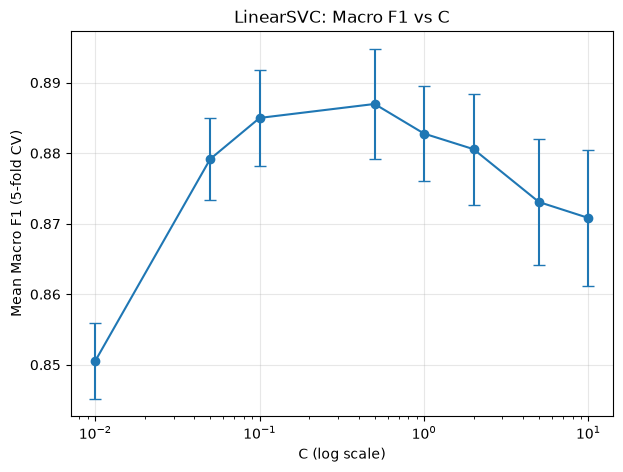

In [35]:
plt.figure(figsize=(7, 5))
plt.errorbar(c_sweep_df["C"], c_sweep_df["mean_macro_f1"], yerr=c_sweep_df["std_macro_f1"], marker="o", capsize=4)
plt.xscale("log")
plt.xlabel("C (log scale)")
plt.ylabel("Mean Macro F1 (5-fold CV)")
plt.title("LinearSVC: Macro F1 vs C")
plt.grid(True, alpha=0.3)
plt.show()

**Conclusion: peak at C=0.5 — adopted.** Mean Macro F1 rises smoothly from C=0.01 (0.8505, underfit) to a clear peak at **C=0.5 (0.8870)**, then falls off past C=1 as the model starts overfitting (down to 0.8708 at C=10, with convergence warnings at high C). The smooth, monotonic shape makes this a trustworthy signal rather than noise. `C=0.5` replaces the default `C=1.0`.

## Experiment: decision-threshold tuning for macro F1 (LinearSVC, C=0.5)

`LinearSVC.decision_function()` gives one raw one-vs-rest score per class; `.predict()` just takes the argmax, which optimizes accuracy, not macro F1. A per-class additive offset was learned (tuned on out-of-fold scores to directly maximize macro F1) and added before taking argmax, so minority classes get a small boost where it helps the evaluation metric.

In [36]:
BEST_C = 0.5


def build_model_pipeline_svc_best_c() -> Pipeline:
    return Pipeline(
        steps=[
            ("features", build_feature_pipeline()),
            (
                "classifier",
                LinearSVC(
                    C=BEST_C,
                    class_weight="balanced",
                    random_state=RANDOM_SEED,
                ),
            ),
        ]
    )

In [37]:
# Collect out-of-fold decision_function scores (not just predicted labels) for every row
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_SEED)

class_order = None
oof_scores = None

for fold_idx, (train_idx, val_idx) in enumerate(skf.split(X, y), start=1):
    X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

    model = build_model_pipeline_svc_best_c()
    model.fit(X_train, y_train)

    if class_order is None:
        class_order = model.named_steps["classifier"].classes_
        oof_scores = np.zeros((len(train), len(class_order)))

    oof_scores[val_idx] = model.decision_function(X_val)
    print(f"Fold {fold_idx} done")

print("Class order:", class_order)

Fold 1 done
Fold 2 done
Fold 3 done
Fold 4 done
Fold 5 done
Class order: ['customer_support' 'other' 'technical_support']


In [38]:
def macro_f1_with_offsets(offsets):
    adjusted = oof_scores + offsets
    preds = class_order[adjusted.argmax(axis=1)]
    return f1_score(y, preds, average="macro")


baseline_macro_f1 = macro_f1_with_offsets(np.zeros(len(class_order)))
print(f"Baseline (no offset, plain argmax) Macro F1: {baseline_macro_f1:.4f}")

Baseline (no offset, plain argmax) Macro F1: 0.8870


In [39]:
# Coordinate ascent: tune one class's offset at a time (holding others fixed), repeat a few rounds
offsets = np.zeros(len(class_order))
grid = np.arange(-3, 3.01, 0.1)

for round_idx in range(3):
    for class_idx in range(len(class_order)):
        best_offset = offsets[class_idx]
        best_score = macro_f1_with_offsets(offsets)
        for candidate in grid:
            trial_offsets = offsets.copy()
            trial_offsets[class_idx] = candidate
            score = macro_f1_with_offsets(trial_offsets)
            if score > best_score:
                best_score = score
                best_offset = candidate
        offsets[class_idx] = best_offset
    print(f"Round {round_idx + 1}: offsets={dict(zip(class_order, offsets))}, Macro F1={macro_f1_with_offsets(offsets):.4f}")

print("\nFinal offsets:", dict(zip(class_order, offsets)))
print(f"Final Macro F1 with tuned offsets: {macro_f1_with_offsets(offsets):.4f}")

Round 1: offsets={'customer_support': np.float64(0.0), 'other': np.float64(-0.09999999999999742), 'technical_support': np.float64(0.0)}, Macro F1=0.8879
Round 2: offsets={'customer_support': np.float64(0.0), 'other': np.float64(-0.09999999999999742), 'technical_support': np.float64(0.0)}, Macro F1=0.8879
Round 3: offsets={'customer_support': np.float64(0.0), 'other': np.float64(-0.09999999999999742), 'technical_support': np.float64(0.0)}, Macro F1=0.8879

Final offsets: {'customer_support': np.float64(0.0), 'other': np.float64(-0.09999999999999742), 'technical_support': np.float64(0.0)}
Final Macro F1 with tuned offsets: 0.8879


In [40]:
preds_before = class_order[oof_scores.argmax(axis=1)]
preds_after = class_order[(oof_scores + offsets).argmax(axis=1)]

print("Before threshold tuning:")
print(classification_report(y, preds_before, digits=4))

print("After threshold tuning:")
print(classification_report(y, preds_after, digits=4))

Before threshold tuning:
                   precision    recall  f1-score   support

 customer_support     0.8450    0.8518    0.8484      3327
            other     0.8665    0.8766    0.8715      3800
technical_support     0.9442    0.9379    0.9410     10642

         accuracy                         0.9087     17769
        macro avg     0.8852    0.8888    0.8870     17769
     weighted avg     0.9090    0.9087    0.9088     17769

After threshold tuning:
                   precision    recall  f1-score   support

 customer_support     0.8397    0.8581    0.8488      3327
            other     0.8838    0.8629    0.8732      3800
technical_support     0.9408    0.9423    0.9416     10642

         accuracy                         0.9096     17769
        macro avg     0.8881    0.8878    0.8879     17769
     weighted avg     0.9097    0.9096    0.9096     17769



**Conclusion: negligible gain — not adopted.** Tuned per-class offsets found essentially only a small `-0.1` nudge for `other`, moving Macro F1 from 0.8870 to 0.8879 (+0.0009) — within the ~0.007-0.008 fold-noise band, not a reliable win. Likely because `class_weight="balanced"` during training was already doing most of the calibration work this technique targets. Not included in the final model to avoid unjustified complexity for an unproven gain.

## Experiment: sublinear_tf on TF-IDF (LinearSVC, C=0.5)

`sublinear_tf=True` replaces raw term frequency with `1 + log(tf)`, damping the effect of a term appearing many times within one document. Tested whether this standard TF-IDF variant helps here, on top of the current best config (LinearSVC, C=0.5).

In [41]:
def build_feature_pipeline_sublinear() -> ColumnTransformer:
    word_tfidf = TfidfVectorizer(
        ngram_range=WORD_NGRAM_RANGE, min_df=WORD_MIN_DF, sublinear_tf=True
    )
    char_tfidf = TfidfVectorizer(
        ngram_range=CHAR_NGRAM_RANGE, min_df=CHAR_MIN_DF, analyzer="char_wb", sublinear_tf=True
    )
    tag_encoder = OneHotEncoder(handle_unknown="ignore")

    return ColumnTransformer(
        transformers=[
            ("word_tfidf", word_tfidf, "feedback"),
            ("char_tfidf", char_tfidf, "feedback"),
            ("tag_ohe", tag_encoder, ["tag"]),
        ]
    )


def build_model_pipeline_sublinear() -> Pipeline:
    return Pipeline(
        steps=[
            ("features", build_feature_pipeline_sublinear()),
            (
                "classifier",
                LinearSVC(
                    C=BEST_C,
                    class_weight="balanced",
                    random_state=RANDOM_SEED,
                ),
            ),
        ]
    )

In [42]:
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_SEED)

fold_macro_f1_sublinear = []
oof_pred_sublinear = pd.Series(index=train.index, dtype=object)

for fold_idx, (train_idx, val_idx) in enumerate(skf.split(X, y), start=1):
    X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

    model = build_model_pipeline_sublinear()
    model.fit(X_train, y_train)
    y_pred = model.predict(X_val)

    macro_f1 = f1_score(y_val, y_pred, average="macro")
    fold_macro_f1_sublinear.append(macro_f1)
    oof_pred_sublinear.iloc[val_idx] = y_pred

    print(f"Fold {fold_idx}: Macro F1 = {macro_f1:.4f}")

print(f"Mean Macro F1 (sublinear_tf): {np.mean(fold_macro_f1_sublinear):.4f} (+/- {np.std(fold_macro_f1_sublinear):.4f})")

train["oof_pred_sublinear"] = oof_pred_sublinear

Fold 1: Macro F1 = 0.8945
Fold 2: Macro F1 = 0.8839
Fold 3: Macro F1 = 0.8999
Fold 4: Macro F1 = 0.8846
Fold 5: Macro F1 = 0.8767
Mean Macro F1 (sublinear_tf): 0.8879 (+/- 0.0082)


In [43]:
print("LinearSVC C=0.5, no sublinear_tf (baseline):")
print(f"Mean Macro F1: {np.mean(c_sweep_df.loc[c_sweep_df['C'] == 0.5, 'mean_macro_f1']):.4f}")
print()
print("LinearSVC C=0.5, with sublinear_tf:")
print(classification_report(train["label"], train["oof_pred_sublinear"], digits=4))

LinearSVC C=0.5, no sublinear_tf (baseline):
Mean Macro F1: 0.8870

LinearSVC C=0.5, with sublinear_tf:
                   precision    recall  f1-score   support

 customer_support     0.8470    0.8536    0.8503      3327
            other     0.8667    0.8779    0.8723      3800
technical_support     0.9444    0.9378    0.9411     10642

         accuracy                         0.9092     17769
        macro avg     0.8861    0.8898    0.8879     17769
     weighted avg     0.9096    0.9092    0.9094     17769



**Conclusion: negligible gain, but free — included.** `sublinear_tf=True` moves Macro F1 from 0.8870 to 0.8879 (+0.0009), again within noise, but since it's a standard, well-understood TF-IDF variant with no downside, it's included in the final config.

## Final model summary

**Configuration:**
- Preprocessing: lowercase, collapse 3+ repeated characters to 2, collapse whitespace, `tag` NaN -> `"missing"`
- Features: word TF-IDF (1,2) `min_df=2` + char_wb TF-IDF (3,5) `min_df=2`, both `sublinear_tf=True`, + tag one-hot (`handle_unknown="ignore"`)
- Classifier: `LinearSVC(C=0.5, class_weight="balanced", random_state=42)`
- No decision-threshold offsets (tested, negligible/unproven gain, not worth the added complexity)

**Results:** 0.8879 mean 5-fold CV Macro F1 (+/- 0.0082) | 0.89901 public leaderboard

**Rejected ideas** (tested, did not help): word trigrams, cross-lingual keyword normalization/dictionary collapsing.

**Known remaining weak spot:** the activation/unlock language subgroup (~6% of data), where the true label itself is only weakly determined by lexical content (55/42 technical/customer split) — likely close to the practical ceiling for a bag-of-words model. This motivates trying a multilingual transformer next, which can read context/intent rather than just vocabulary.